# Análise exploratória: Cirrhosis Patient Survival Prediction

In [1]:
%pip install ucimlrepo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo 

plt.style.use("seaborn-v0_8-whitegrid")
plt.style.use("ggplot")
plt.style.use("bmh")
  
# fetch dataset 
dataset = fetch_ucirepo(id=878) 
  
# data (as pandas dataframes) 
X = dataset.data.features 
y = dataset.data.targets 
  
# metadata 
print(dataset.metadata) 
  
# variable information 
print(dataset.variables) 

dataset.variables

{'uci_id': 878, 'name': 'Cirrhosis Patient Survival Prediction', 'repository_url': 'https://archive.ics.uci.edu/dataset/878/cirrhosis+patient+survival+prediction+dataset-1', 'data_url': 'https://archive.ics.uci.edu/static/public/878/data.csv', 'abstract': 'Utilize 17 clinical features for predicting survival state of patients with liver cirrhosis. The survival states include 0 = D (death), 1 = C (censored), 2 = CL (censored due to liver transplantation).', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 418, 'num_features': 17, 'feature_types': ['Real', 'Categorical'], 'demographics': ['Age', 'Sex'], 'target_col': ['Status'], 'index_col': ['ID'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5R02G', 'creators': ['E. Dickson', 'P. Grambsch', 'T. Fleming', 'L. Fisher', 'A. Langworthy'], 'intro_paper': {'ID': 296, 'type'

,name,role,type,demographic,description,units,missing_values
0,ID,ID,Integer,None,unique identifier,None,no
1,N_Days,Other,Integer,None,number of days between registration and the ea...,None,no
2,Status,Target,Categorical,None,"status of the patient C (censored), CL (censor...",None,no
3,Drug,Feature,Categorical,None,type of drug D-penicillamine or placebo,None,yes
4,Age,Feature,Integer,Age,age,days,no
5,Sex,Feature,Categorical,Sex,M (male) or F (female),None,no
6,Ascites,Feature,Categorical,None,presence of ascites N (No) or Y (Yes),None,yes
7,Hepatomegaly,Feature,Categorical,None,presence of hepatomegaly N (No) or Y (Yes),None,yes
8,Spiders,Feature,Categorical,None,presence of spiders N (No) or Y (Yes),None,yes
9,Edema,Feature,Categorical,None,presence of edema N (no edema and no diuretic ...,None,no


## Limpeza

In [3]:
df = dataset.data.original.replace("NaNN", np.nan)
numericas = ["Age", "Bilirubin", "Cholesterol", "Albumin", "Copper", "Alk_Phos",
             "SGOT", "Tryglicerides", "Platelets", "Prothrombin"]
df[numericas] = df[numericas].apply(pd.to_numeric)
df[numericas].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,418.0,18533.351675,3815.845055,9598.00,15644.5000,18628.00,21272.50,28650.00
Bilirubin,418.0,3.220813,4.407506,0.30,0.8000,1.40,3.40,28.00
Cholesterol,284.0,369.510563,231.944545,120.00,249.5000,309.50,400.00,1775.00
Albumin,418.0,3.497440,0.424972,1.96,3.2425,3.53,3.77,4.64
Copper,310.0,97.648387,85.613920,4.00,41.2500,73.00,123.00,588.00
Alk_Phos,312.0,1982.655769,2140.388824,289.00,871.5000,1259.00,1980.00,13862.40
SGOT,312.0,122.556346,56.699525,26.35,80.6000,114.70,151.90,457.25
Tryglicerides,282.0,124.702128,65.148639,33.00,84.2500,108.00,151.00,598.00
Platelets,407.0,257.024570,98.325585,62.00,188.5000,251.00,318.00,721.00
Prothrombin,416.0,10.731731,1.022000,9.00,10.0000,10.60,11.10,18.00


Sex
F    374
M     44
Name: count, dtype: int64
Sex
F    0.895
M    0.105
Name: proportion, dtype: float64


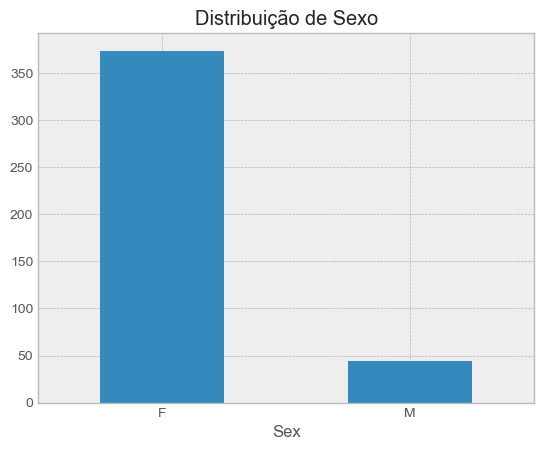

In [4]:
print(df['Sex'].value_counts())
print(df['Sex'].value_counts(normalize=True).round(3))
df['Sex'].value_counts().plot.bar(rot=0, title="Distribuição de Sexo")
plt.show()

## Variável-alvo (`Status`)
C = vivo ao fim do acompanhamento, CL = vivo por transplante de fígado, D = óbito.

Status
C     232
D     161
CL     25
Name: count, dtype: int64
Status
C     0.555
D     0.385
CL    0.060
Name: proportion, dtype: float64


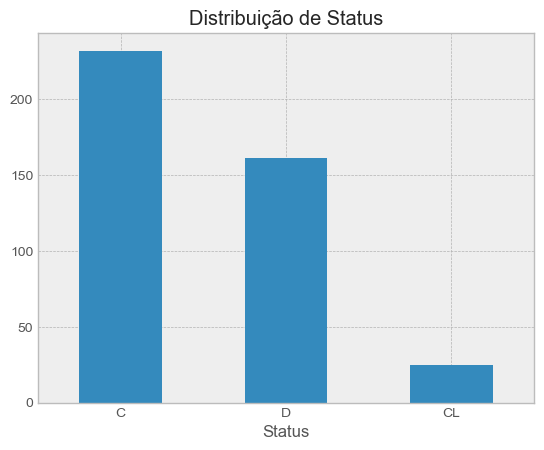

In [5]:
print(df["Status"].value_counts())
print(df["Status"].value_counts(normalize=True).round(3))
df["Status"].value_counts().plot.bar(rot=0, title="Distribuição de Status")
plt.show()

## Valores ausentes

In [6]:
ausentes = df.isna().sum()
ausentes[ausentes > 0].sort_values(ascending=False)

Tryglicerides    136
Cholesterol      134
Copper           108
Drug             106
Spiders          106
Hepatomegaly     106
Ascites          106
Alk_Phos         106
SGOT             106
Platelets         11
Stage              6
Prothrombin        2
dtype: int64

In [7]:
print("Pacientes sem 'Drug':", df["Drug"].isna().sum())
print("Linhas completas:", len(df.dropna()), "de", len(df))

Pacientes sem 'Drug': 106
Linhas completas: 276 de 418


## Atributos constantes e duplicados

In [8]:
print("Atributos constantes:", [c for c in df.columns if df[c].nunique() <= 1])
print("Linhas duplicadas:", df.drop(columns="ID").duplicated().sum())

Atributos constantes: []
Linhas duplicadas: 0


## Correlações

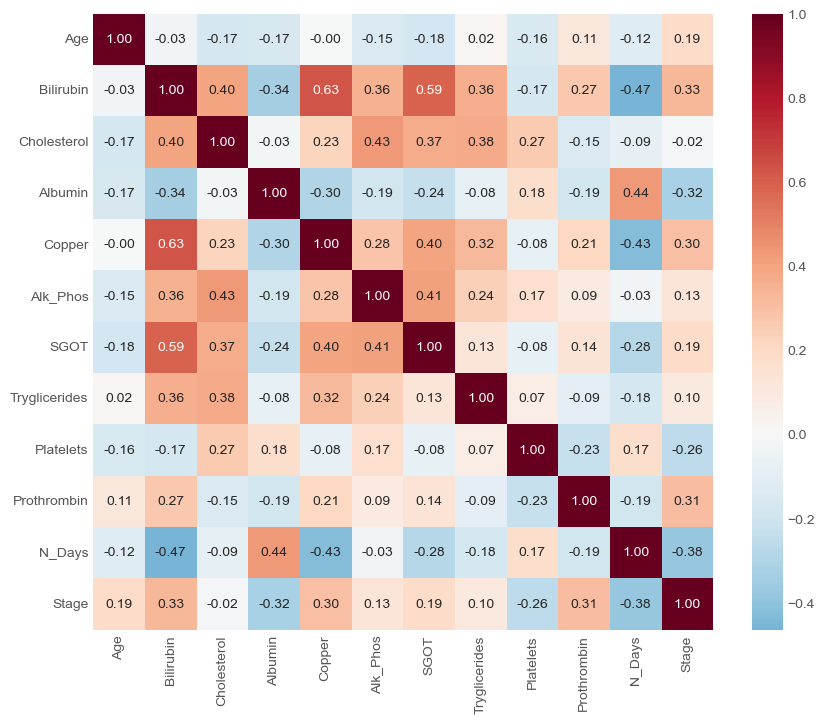

In [9]:
# spearman por que os dados não são normais e não são lineares
corr = df[numericas + ["N_Days", "Stage"]].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.show()

In [10]:
%pip install xgboost scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [11]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

SEED = 42

In [12]:
dados = df[df["Drug"].notna()].copy()

y = (dados["Status"] == "D").astype(int)

# tudo menos ID, Status e N_Days (N_Days seria vazamento de informação)
X = dados.drop(columns=["ID", "Status", "N_Days"])

# Categóricas -> números
X["Age"] = X["Age"] / 365.25  # dias -> anos
X["Drug"] = (X["Drug"] == "D-penicillamine").astype(int)
X["Sex"] = (X["Sex"] == "M").astype(int)
for col in ["Ascites", "Hepatomegaly", "Spiders"]:
    X[col] = (X[col] == "Y").astype(int)
X["Edema"] = X["Edema"].map({"N": 0, "S": 0.5, "Y": 1}) # ordinal: sem edema, edema sem diurético, edema com diurético

print("X shape:", X.shape)
print("Óbitos:", y.sum(), f"({y.mean():.1%})")
print("Ausentes que sobraram:")
print(X.isna().sum()[X.isna().sum() > 0])

X shape: (312, 17)
Óbitos: 125 (40.1%)
Ausentes que sobraram:
Cholesterol      28
Copper            2
Tryglicerides    30
Platelets         4
dtype: int64


In [13]:
modelos = {
    "Referência": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=SEED)),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                             eval_metric="logloss", n_jobs=-1, random_state=SEED),
}

In [14]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

resultados = []
importancias = []

for rodada, (treino, teste) in enumerate(cv.split(X, y)):
    X_tr, X_te = X.iloc[treino], X.iloc[teste]
    y_tr, y_te = y.iloc[treino], y.iloc[teste]

    for nome, modelo in modelos.items():
        modelo.fit(X_tr, y_tr)
        prob = modelo.predict_proba(X_te)[:, 1]
        pred = modelo.predict(X_te)
        resultados.append({
            "modelo": nome, "rodada": rodada,
            "AUC": roc_auc_score(y_te, prob),
            "F1": f1_score(y_te, pred, zero_division=0),
            "Acurácia": accuracy_score(y_te, pred),
        })

        if nome != "Referência (classe majoritária)":
            imp = permutation_importance(modelo, X_te, y_te, scoring="roc_auc",
                                         n_repeats=10, random_state=SEED, n_jobs=-1)
            importancias.append(pd.DataFrame({
                "modelo": nome, "rodada": rodada,
                "atributo": X.columns, "importancia": imp.importances_mean,
            }))

resultados = pd.DataFrame(resultados)
importancias = pd.concat(importancias)

In [15]:
#tabela de desempenho
tabela = resultados.groupby("modelo")[["AUC", "F1", "Acurácia"]].agg(["mean", "std"]).round(3)
tabela.sort_values(("AUC", "mean"), ascending=False)

AUC            F1        Acurácia       
                      mean    std   mean    std     mean    std
modelo                                                         
Regressão Logística  0.857  0.058  0.718  0.088    0.789  0.060
Random Forest        0.855  0.055  0.748  0.063    0.808  0.045
XGBoost              0.836  0.054  0.718  0.065    0.783  0.045
Referência           0.500  0.000  0.000  0.000    0.599  0.003

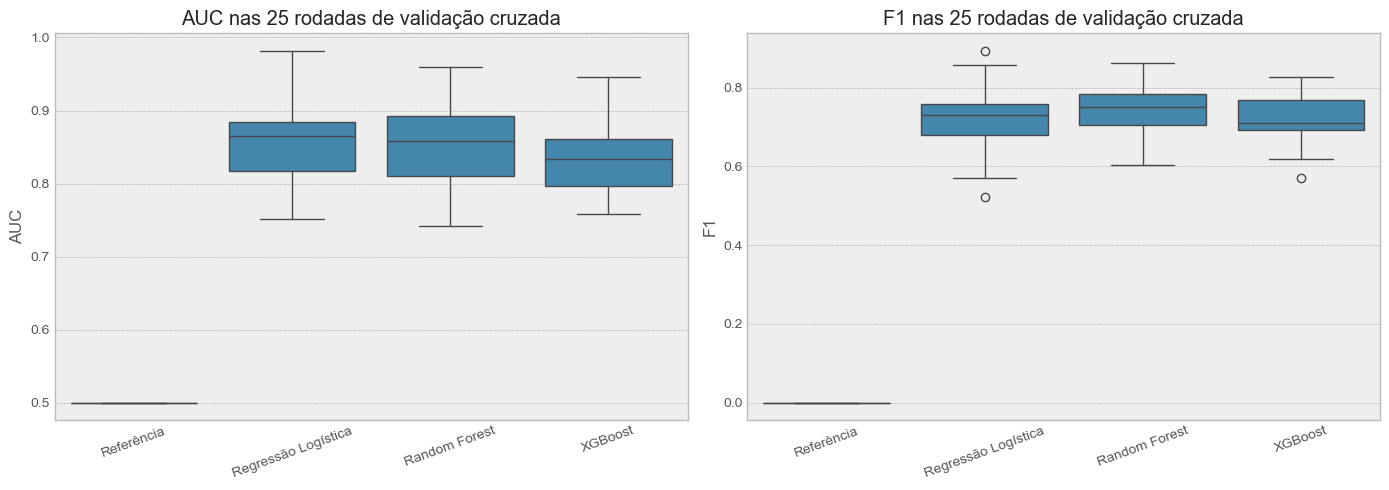

In [16]:
#boxplot das métricas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metrica in zip(axes, ["AUC", "F1"]):
    sns.boxplot(data=resultados, x="modelo", y=metrica, ax=ax)
    ax.set_title(f"{metrica} nas 25 rodadas de validação cruzada")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

In [17]:
# os modelos diferem de verdade?
# Teste de Wilcoxon pareado sobre as AUCs das mesmas rodadas.
from itertools import combinations
from scipy.stats import wilcoxon, t as t_student

auc = resultados.pivot(index="rodada", columns="modelo", values="AUC")
for a, b in combinations(["Regressão Logística", "Random Forest", "XGBoost"], 2):
    p = wilcoxon(auc[a], auc[b]).pvalue
    print(f"{a} x {b}: diferença média de AUC = {(auc[a] - auc[b]).mean():+.3f}, p = {p:.3f}")

Regressão Logística x Random Forest: diferença média de AUC = +0.002, p = 0.508
Regressão Logística x XGBoost: diferença média de AUC = +0.021, p = 0.034
Random Forest x XGBoost: diferença média de AUC = +0.019, p = 0.008


In [18]:
from statsmodels.stats.multitest import multipletests

k = len(auc)
t_crit = t_student.ppf(0.975, k - 1)

linhas = []
for a, b in combinations(["Regressão Logística", "Random Forest", "XGBoost"], 2):
    d = auc[a] - auc[b]
    ep = np.sqrt((1/k + 1/4) * d.var(ddof=1))
    linhas.append({"comparação": f"{a} - {b}", 
                   "diferença": d.mean(),
                   "IC inf": d.mean() - t_crit * ep, "IC sup": d.mean() + t_crit * ep,
                   "p": 2 * t_student.sf(abs(d.mean() / ep), k - 1)})

tabela3 = pd.DataFrame(linhas)
tabela3["p (Holm)"] = multipletests(tabela3["p"], method="holm")[1]
tabela3.round(3)

,comparação,diferença,IC inf,IC sup,p,p (Holm)
0,Regressão Logística - Random Forest,0.002,-0.025,0.028,0.905,0.905
1,Regressão Logística - XGBoost,0.021,-0.026,0.067,0.368,0.794
2,Random Forest - XGBoost,0.019,-0.015,0.053,0.265,0.794


In [19]:
# tabela de importância
# importância por permutação: quanto a AUC cai quando embaralhamos cada atributo
imp_media = (importancias.groupby(["atributo", "modelo"])["importancia"].mean()
             .unstack().sort_values("XGBoost", ascending=False))
imp_media.round(3)

modelo,Random Forest,Referência,Regressão Logística,XGBoost
atributo,,,,
Prothrombin,0.044,0.0,0.044,0.068
Age,0.017,0.0,0.029,0.042
Bilirubin,0.032,0.0,0.028,0.040
Copper,0.014,0.0,0.009,0.015
SGOT,0.008,0.0,0.019,0.012
Alk_Phos,0.006,0.0,0.021,0.006
Ascites,0.006,0.0,0.021,0.003
Cholesterol,-0.001,0.0,0.000,0.003
Sex,0.001,0.0,0.003,0.000


IC acima de zero:
 modelo         Regressão Logística  Random Forest  XGBoost
atributo                                                  
Age                           True           True     True
Albumin                      False          False    False
Alk_Phos                      True          False    False
Ascites                       True           True    False
Bilirubin                     True           True     True
Cholesterol                  False          False    False
Copper                       False           True    False
Drug                         False          False    False
Edema                        False          False    False
Hepatomegaly                 False          False    False
Platelets                    False          False    False
Prothrombin                   True           True     True
SGOT                          True          False    False
Sex                          False          False    False
Spiders                      False   

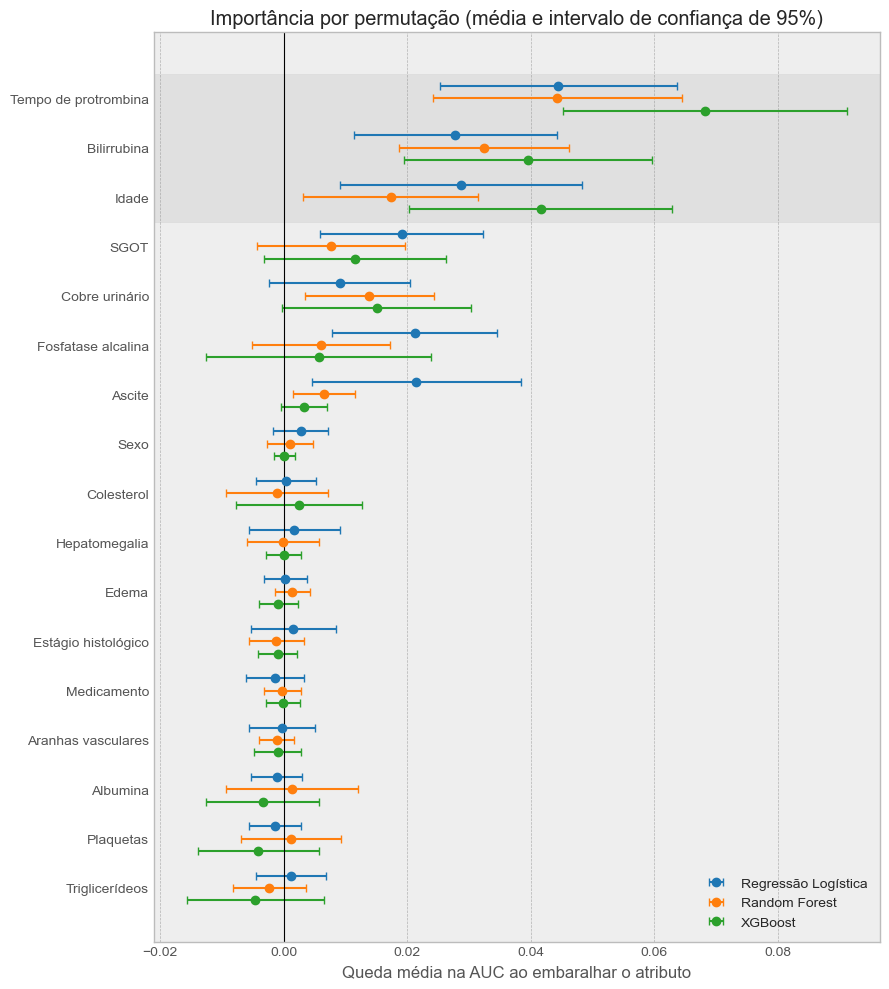

In [20]:
nomes = {"Prothrombin": "Tempo de protrombina", 
         "Age": "Idade", 
         "Bilirubin": "Bilirrubina",
         "Copper": "Cobre urinário", 
         "SGOT": "SGOT", 
         "Alk_Phos": "Fosfatase alcalina",
         "Ascites": "Ascite", 
         "Cholesterol": "Colesterol", 
         "Sex": "Sexo",
         "Hepatomegaly": "Hepatomegalia", 
         "Drug": "Medicamento", 
         "Edema": "Edema",
         "Stage": "Estágio histológico", 
         "Spiders": "Aranhas vasculares",
         "Albumin": "Albumina", 
         "Platelets": "Plaquetas", 
         "Tryglicerides": "Triglicerídeos"
         }

modelos_comp = ["Regressão Logística", "Random Forest", "XGBoost"]
cores = ["tab:blue", "tab:orange", "tab:green"]


stats = (importancias[importancias["modelo"].isin(modelos_comp)]
         .groupby(["atributo", "modelo"])["importancia"].agg(["mean", "std"]))
media = stats["mean"].unstack()[modelos_comp]
desvio = stats["std"].unstack()[modelos_comp]
FATOR_IC = t_student.ppf(0.975, df=24) * np.sqrt(1/25 + 1/4)
erro_ic = FATOR_IC * desvio
print("IC acima de zero:\n", (media - erro_ic > 0))

ordem = media.mean(axis=1).sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 10))
y = np.arange(len(ordem))
for i, (modelo, cor) in enumerate(zip(modelos_comp, cores)):
    ax.errorbar(media.loc[ordem, modelo], y + (i - 1) * 0.25, xerr=erro_ic.loc[ordem, modelo], fmt="o", color=cor, ecolor=cor, elinewidth=1.5, capsize=3, markersize=6, label=modelo)
ax.axvline(0, color="black", linewidth=0.8)
ax.axhspan(-0.5, 2.5, color="grey", alpha=0.12)
ax.set_yticks(y)
ax.set_yticklabels([nomes[a] for a in ordem])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("Queda média na AUC ao embaralhar o atributo")
ax.set_title("Importância por permutação (média e intervalo de confiança de 95%)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [21]:
def queda(modelo, X_te, y_te, cols):
    base = roc_auc_score(y_te, modelo.predict_proba(X_te)[:, 1])
    Xp, quedas = X_te.copy(), []
    for _ in range(10):
        Xp[cols] = X_te[cols].values[rng.permutation(len(X_te))]
        quedas.append(base - roc_auc_score(y_te, modelo.predict_proba(Xp)[:, 1]))
    return np.mean(quedas)

In [22]:
# TESTE
# resposta ao parecer
# Importância agrupada da albumina.

from sklearn.base import clone
alvo = (dados["Status"] == "D").astype(int)
rng = np.random.default_rng(SEED)

linhas = []
for tr, te in cv.split(X, alvo):
    for nome in modelos_comp:
        m = clone(modelos[nome]).fit(X.iloc[tr], alvo.iloc[tr])
        Xte, yte = X.iloc[te], alvo.iloc[te]
        linhas.append({"modelo": nome,
                       "par": queda(m, Xte, yte, ["Albumin", "Bilirubin"]),
                       "soma": queda(m, Xte, yte, ["Albumin"]) + queda(m, Xte, yte, ["Bilirubin"])})

r = pd.DataFrame(linhas).assign(excesso=lambda d: d["par"] - d["soma"])
tabela4 = r.groupby("modelo").agg(par=("par", "mean"), soma=("soma", "mean"),
                                  excesso=("excesso", "mean"), dp=("excesso", "std"))
tabela4["ic_inf"] = tabela4["excesso"] - FATOR_IC * tabela4["dp"]
tabela4["ic_sup"] = tabela4["excesso"] + FATOR_IC * tabela4["dp"]
tabela4.round(3)

,par,soma,excesso,dp,ic_inf,ic_sup
modelo,,,,,,
Random Forest,0.041,0.030,0.011,0.015,-0.006,0.027
Regressão Logística,0.028,0.028,-0.000,0.010,-0.011,0.011
XGBoost,0.041,0.032,0.009,0.014,-0.007,0.025


In [23]:
for modelo in imp_media.columns:
    print(f"{modelo}: {', '.join(imp_media[modelo].nlargest(5).index)}")

Random Forest: Prothrombin, Bilirubin, Age, Copper, SGOT
Referência: Prothrombin, Age, Bilirubin, Copper, SGOT
Regressão Logística: Prothrombin, Age, Bilirubin, Ascites, Alk_Phos
XGBoost: Prothrombin, Age, Bilirubin, Copper, SGOT


In [24]:
# TESTE
# stratified k-fold cross-validation para o parecer

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

space = {
    "Regressão Logística": {"logisticregression__C": np.logspace(-3, 2, 20)},
    "Random Forest": {"randomforestclassifier__n_estimators": [100, 300, 500],
                      "randomforestclassifier__max_depth": [None, 3, 5, 10],
                      "randomforestclassifier__min_samples_leaf": [1, 3, 5, 10],
                      "randomforestclassifier__max_features": ["sqrt", 0.5, None]},
    "XGBoost": {"n_estimators": [100, 300, 500], 
                "max_depth": [2, 3, 4, 6],
                "learning_rate": [0.01, 0.05, 0.1], 
                "subsample": [0.7, 1.0],
                "colsample_bytree": [0.7, 1.0]},
}
cv_interno = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

linhas, escolhidos = [], []
for rodada, (tr, te) in enumerate(cv.split(X, alvo)):
    for nome, espaco in space.items():
        busca = RandomizedSearchCV(clone(modelos[nome]), espaco, n_iter=20, scoring="roc_auc", cv=cv_interno, random_state=SEED, n_jobs=-1)
        busca.fit(X.iloc[tr], alvo.iloc[tr])
        prob = busca.predict_proba(X.iloc[te])[:, 1]
        linhas.append({"modelo": nome, "rodada": rodada, "AUC": roc_auc_score(alvo.iloc[te], prob)})
        escolhidos.append({"modelo": nome, **busca.best_params_})

auc_aninhado = pd.DataFrame(linhas).pivot(index="rodada", columns="modelo", values="AUC")
print(auc_aninhado.agg(["mean", "std"]).round(3), "\n")

#mesmo teste t corrigido + Holm 
linhas = []
for a, b in combinations(modelos_comp, 2):
    d = auc_aninhado[a] - auc_aninhado[b]
    ep = np.sqrt((1/k + 1/4) * d.var(ddof=1))
    linhas.append({"comparação": f"{a} - {b}", "diferença": d.mean(),
                   "IC inf": d.mean() - t_crit * ep, "IC sup": d.mean() + t_crit * ep,
                   "p": 2 * t_student.sf(abs(d.mean() / ep), k - 1)})
tabela_aninhada = pd.DataFrame(linhas)
tabela_aninhada["p (Holm)"] = multipletests(tabela_aninhada["p"], method="holm")[1]
print(tabela_aninhada.round(3), "\n")

# hiperparâmetros mais escolhidos
print(pd.DataFrame(escolhidos).groupby("modelo").agg(lambda s: s.astype(str).value_counts().index[0]))

modelo  Random Forest  Regressão Logística  XGBoost
mean            0.853                0.858    0.844
std             0.054                0.057    0.057 

                            comparação  diferença  IC inf  IC sup      p  \
0  Regressão Logística - Random Forest      0.006  -0.023   0.034  0.696   
1        Regressão Logística - XGBoost      0.014  -0.027   0.056  0.477   
2              Random Forest - XGBoost      0.009  -0.017   0.034  0.481   

   p (Holm)  
0       1.0  
1       1.0  
2       1.0   

                    logisticregression__C  \
modelo                                      
Random Forest                         nan   
Regressão Logística   0.02069138081114789   
XGBoost                               nan   

                    randomforestclassifier__n_estimators  \
modelo                                                     
Random Forest                                      300.0   
Regressão Logística                                  nan   
XGBoost      